# Staging and the significant increase in credit risk

**Question:** Which loans of a small-business book has the bank moved from the 12-month ECL to the lifetime ECL, why those and not others, and how many more or fewer would move if one parameter of the rule moved?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- compare the PD a loan had at origination with the PD it has at the reporting date on the same window, and annualise both so loans of different remaining life compare;
- apply the relative-and-absolute rule of significant increase in credit risk (SICR) with the threefold backstop, and say what each parameter of the policy does to the number of loans in Stage 2;
- allocate a stage with the 30 and 90 days past due presumptions, forbearance, the watch list and the low credit risk exemption, and read which trigger fired and why it took precedence;
- hold a cured loan in Stage 2 for a probation period, and report the target of a collective transfer without adding it to the allowance;
- read the stage flows and the coverage by stage of a committed reporting date, and compare a calm date with a stressed one.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
TRIGGER = {
    "none": "none",
    "relative-absolute": "relative and absolute",
    "threefold": "three times",
    "dpd-backstop": "days past due backstop",
    "default": "default",
    "forbearance": "forbearance",
    "watch-list": "watch list",
    "collective": "collective transfer",
    "cure-probation": "cure probation",
}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 (SBA 7(a) small-business loans as the public twin of a mortgage book; U.S. Government Works, licence class `mirror-allowed`) at two reporting dates: 2008-12-31, in the financial crisis, and 2019-12-31, a calm year. Each artifact holds, besides the term structures of notebook 01:

- `outputs.settings.sicr`: the staging policy the pipeline used (the multiplier schedule, the absolute floor, the threefold ratio, the 30 and 90 days);
- `outputs.account_curves`: a sample of 40 accounts with their cumulative PD from origination and from the reporting date, quarter by quarter for three years;
- `outputs.sicr_points`: a sample of 400 accounts with their annualised PD at origination and now, the stage and the trigger the pipeline assigned;
- `outputs.stage_flows` and `outputs.stage_summary`: the movement of the whole book between the two year-end dates and its stage totals.

**What the file does not hold:** delinquency, forbearance or watch-list history (finding `F-NO-DELINQUENCY`). In C06 only the quantitative SICR test can move a loan to Stage 2, and the days past due are zero. The cases of the qualitative triggers below are therefore **constructed accounts**, labelled as such, to show how the engine decides.

The next cell loads both artifacts, builds the engine's `StagingPolicy` from the committed settings and prints the policy and the engine versions.

In [2]:
# Load the two reporting dates and build the staging policy from the committed settings
from riskvalidation.provisions import staging, term_structure as tsm

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C06"
crisis = json.loads((DERIVED / "rd-2008-12.json").read_text(encoding="utf-8"))
calm = json.loads((DERIVED / "rd-2019-12.json").read_text(encoding="utf-8"))
out = crisis["outputs"]
sicr = out["settings"]["sicr"]
schedule = tuple((row["pd_origination_upper"], row["multiplier"]) for row in sicr["multiplier_schedule"])
policy = staging.StagingPolicy(
    multiplier_schedule=schedule,
    absolute_floor=sicr["absolute_floor"],
    threefold_ratio=sicr["threefold_ratio"],
    dpd_backstop=sicr["dpd_backstop"],
    default_dpd=sicr["default_dpd"],
    probation_months=out["settings"]["probation_months"],
    low_credit_risk_pd=sicr["low_credit_risk_pd"],
)
baked = (crisis["provenance"]["riskvalidation_version"], calm["provenance"]["riskvalidation_version"])
print("engine that baked the artifacts:", *baked)
print("engine installed now:", md.version("riskvalidation"))
print("multiplier schedule (origination PD up to, multiplier):", policy.multiplier_schedule)
print("absolute floor:", policy.absolute_floor, "| threefold ratio:", policy.threefold_ratio)
print("days past due: presumption and default:", policy.dpd_backstop, policy.default_dpd)

engine that baked the artifacts: 1.0.1 1.0.1
engine installed now: 1.0.1
multiplier schedule (origination PD up to, multiplier): ((0.01, 4.0), (0.05, 2.5), (0.5, 1.5))
absolute floor: 0.005 | threefold ratio: 3.0
days past due: presumption and default: 30 90


## Method

The staging of IFRS 9 compares the credit risk now with the risk at initial recognition (IFRS 9 5.5.3, 5.5.9). The standard does not prescribe how. Contraste follows the practice its research found (GPPC 2016, section 2.7.2; BCBS d350, annex A26; EBA/Rep/2021/35 and EBA/Rep/2023/36 paragraph 32). Four elements:

**1. The same window.** The origination expectation for the remaining window is the forward PD from the term structure estimated at origination, $PD^{\mathrm{orig}}(a, a+H) = \frac{S^{(t_0)}(a) - S^{(t_0)}(a+H)}{S^{(t_0)}(a)}$, and the current estimate is $PD^{\mathrm{rep}}(0, H)$ from the term structure at the reporting date. Both are annualised so that loans of different remaining life compare: $\overline{PD} = 1 - (1 - PD)^{1/H_{\mathrm{yrs}}}$. The geometric form is Contraste's documented convention; the EBA states that it compares annualised lifetime PDs and, in the passages read, does not state the formula (UNVERIFIED as the EBA's).

**2. The quantitative rule** (relative and absolute, with the threefold backstop), with $m(\cdot)$ a multiplier that does not rise with the origination PD and $\delta$ an absolute floor:

$$\mathrm{SICR} = \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge m(\overline{PD}^{\mathrm{orig}}) \;\wedge\; \overline{PD}^{\mathrm{rep}} - \overline{PD}^{\mathrm{orig}} \ge \delta\Bigr] \;\vee\; \mathbb{1}\Bigl[\tfrac{\overline{PD}^{\mathrm{rep}}}{\overline{PD}^{\mathrm{orig}}} \ge 3\Bigr]$$

**3. The stage.** Stage 3 if the loan is in default (defaulted, or 90 or more days past due, B5.5.37); otherwise Stage 2 if any trigger fires (more than 30 days past due as a rebuttable presumption, 5.5.11; forbearance; watch list; a collective transfer; the quantitative rule); otherwise Stage 1. The low credit risk exemption (5.5.10) suppresses only the two quantitative triggers. The engine states the precedence of the triggers and returns the one that decided.

**4. The way back and the collective view.** A loan that is back in Stage 1 is held in Stage 2 for a probation period (B5.5.27, a policy parameter, not a number of the standard). When a risk driver is known only for a segment, a share $\pi_g$ of the segment is moved to Stage 2: $\mathrm{amount}_g = \pi_g \sum_{i \in g} \mathrm{GCA}_i$ (B5.5.6).

The thresholds are Contraste's configurable policy, not regulation: the threefold ratio is a supervisory expectation (EBA/Rep/2023/36 paragraph 32), not IFRS 9.

### Step 1: origination against the reporting date, on the same window

The artifact keeps, for 40 accounts, the cumulative PD over the first three years from origination and from the reporting date. We take one Stage 1 account and one Stage 2 account, convert each cumulative PD at month 36 into an annualised PD with `annualise_pd` over the 3 years, and ask `sicr_quantitative` whether the pair is a significant increase under the committed policy. The figure draws the two curves of each account, so the gap that the rule reads is visible before it is a ratio.

A0001 | annualised PD, origination and now: 0.002863 0.003408
   ratio: 1.19 | difference: 0.000545 | significant increase: no
A0005 | annualised PD, origination and now: 0.0114 0.030646
   ratio: 2.688 | difference: 0.019246 | significant increase: yes


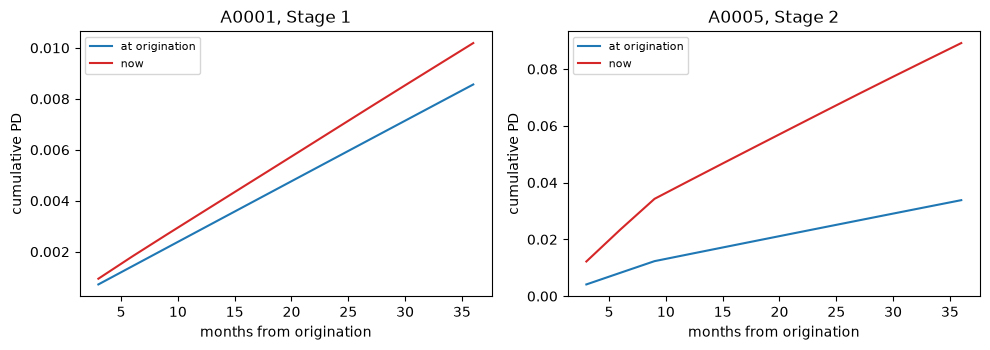

In [3]:
# Annualise the PD of a Stage 1 and a Stage 2 account, test them and draw their curves
curves = {c["account_id"]: c for c in out["account_curves"]}
picked = [next(a for a, c in curves.items() if c["stage"] == s) for s in ("stage1", "stage2")]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, account_id in zip(axes, picked):
    c = curves[account_id]
    ann_orig = float(tsm.annualise_pd(np.array([c["origination_cumulative_pd"][-1]]), 3.0)[0])
    ann_now = float(tsm.annualise_pd(np.array([c["current_cumulative_pd"][-1]]), 3.0)[0])
    flagged = bool(staging.sicr_quantitative(np.array([ann_orig]), np.array([ann_now]), policy)[0])
    print(account_id, "| annualised PD, origination and now:", round(ann_orig, 6), round(ann_now, 6))
    print("   ratio:", round(ann_now / ann_orig, 3), "| difference:", round(ann_now - ann_orig, 6),
          "| significant increase:", "yes" if flagged else "no")
    ax.plot(c["months"], c["origination_cumulative_pd"], color="tab:blue", label="at origination")
    ax.plot(c["months"], c["current_cumulative_pd"], color="tab:red", label="now")
    ax.set_xlabel("months from origination")
    ax.set_ylabel("cumulative PD")
    ax.set_title(f"{account_id}, Stage {c['stage'][-1]}")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Account A0001 sits in Stage 1: its current curve lies only a little above its curve at origination, and the annualised PD went from 0.0029 to 0.0034, a ratio of 1.19, far from any multiplier of the schedule. Account A0005 is the opposite: its cumulative PD at 36 months grew from 3.4% to 8.9%, an annualised ratio of 2.69 and a difference of 0.0192. Its origination PD falls in the band whose multiplier is 2.5, so both the ratio and the absolute floor are met and the engine flags it.

### Step 2: the rule on 400 accounts

`sicr_points` holds the annualised PDs of 400 accounts at origination and now. We pass them to `allocate_stages` with zero days past due and no qualitative flag, because the file has none, and let the engine assign the stage and name the trigger that decided. The figure plots every account by its two PDs on logarithmic axes. The dotted line is equal PD and the dashed line is three times the origination PD; the rule can act only above the multiplier of the account's band.

trigger: none | accounts: 384
trigger: relative and absolute | accounts: 16
accounts: 400 | share in Stage 2: 0.04
largest ratio of the sample: 2.764


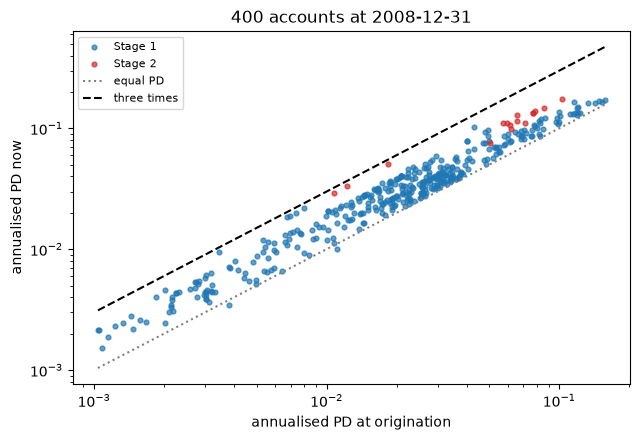

In [4]:
# Allocate the stages of the 400 sampled accounts with the engine, count the triggers and draw the accounts
points = out["sicr_points"]
orig = np.array([p["pd_origination_annualised"] for p in points])
now = np.array([p["pd_current_annualised"] for p in points])
no_flag = np.zeros(len(points), dtype=bool)
no_dpd = np.zeros(len(points), dtype=np.int64)
result = staging.allocate_stages(orig, now, no_dpd, no_flag, no_flag, no_flag, policy)
for trigger in sorted({str(t) for t in result.trigger}):
    print("trigger:", TRIGGER[trigger], "| accounts:", int(np.sum(result.trigger == trigger)))
print("accounts:", len(points), "| share in Stage 2:", round(float(np.mean(result.stage == 2)), 4))
print("largest ratio of the sample:", round(float((now / orig).max()), 3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for stage_no, color in ((1, "tab:blue"), (2, "tab:red")):
    mask = result.stage == stage_no
    ax.scatter(orig[mask], now[mask], s=12, color=color, alpha=0.7, label=f"Stage {stage_no}")
grid = np.array([orig.min(), orig.max()])
ax.plot(grid, grid, color="grey", linestyle=":", label="equal PD")
ax.plot(grid, 3.0 * grid, color="black", linestyle="--", label="three times")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("annualised PD at origination")
ax.set_ylabel("annualised PD now")
ax.set_title("400 accounts at 2008-12-31")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Sixteen of the 400 accounts, 4% of the sample, land in Stage 2 and every one of them by the relative-and-absolute rule. They are the red points that rise well above the line of equal PD. No account reaches three times its origination PD: the largest ratio of the sample is 2.76, so the threefold backstop, which would catch a loan whose risk has tripled whatever its band, never acts on this sample.

### Step 3: what each parameter of the policy does

A validator asks how many loans move when a parameter moves. The cell reruns `sicr_quantitative` on the same 400 accounts with the absolute floor $\delta$ at 0, 0.005 (the committed value), 0.01 and 0.02, with the threefold ratio at 2, 3 and 5, and with the whole multiplier schedule scaled by 0.75, 1 and 1.25. The policy is an immutable dataclass, so `dataclasses.replace` makes a new one and leaves the committed policy intact. Each parameter gets a panel of the number of loans flagged.

committed policy: flagged of 400 : 16
absolute floor: (0.0, 0.005, 0.01, 0.02) -> [16, 16, 16, 15]
threefold ratio: (2.0, 3.0, 5.0) -> [35, 16, 16]
scale of the multipliers: (0.75, 1.0, 1.25) -> [109, 16, 2]


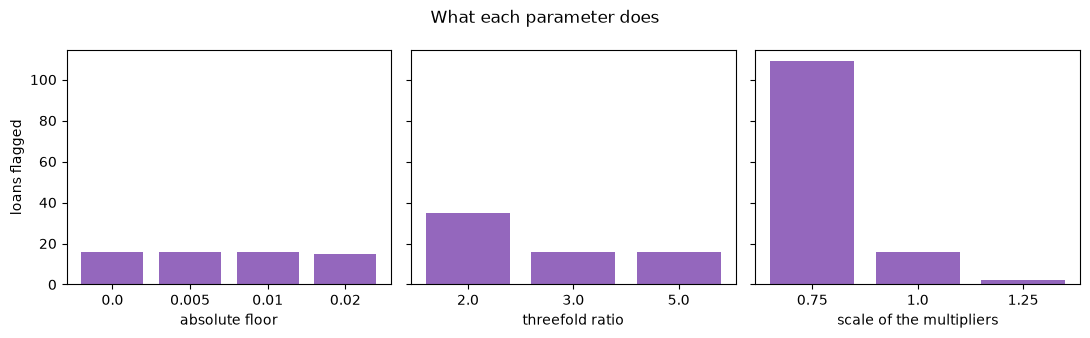

In [5]:
# Count the flagged loans while one parameter moves and the others stay as committed
floors, ratios, scales = (0.0, 0.005, 0.01, 0.02), (2.0, 3.0, 5.0), (0.75, 1.0, 1.25)
flagged = staging.sicr_quantitative(orig, now, policy)
by_floor, by_ratio, by_scale = [], [], []
for floor in floors:
    by_floor.append(int(staging.sicr_quantitative(orig, now, dataclasses.replace(policy, absolute_floor=floor)).sum()))
for ratio in ratios:
    by_ratio.append(int(staging.sicr_quantitative(orig, now, dataclasses.replace(policy, threefold_ratio=ratio)).sum()))
for scale in scales:
    scaled = tuple((upper, mult * scale) for upper, mult in policy.multiplier_schedule)
    new_policy = dataclasses.replace(policy, multiplier_schedule=scaled)
    by_scale.append(int(staging.sicr_quantitative(orig, now, new_policy).sum()))
print("committed policy: flagged of", len(points), ":", int(flagged.sum()))
print("absolute floor:", floors, "->", by_floor)
print("threefold ratio:", ratios, "->", by_ratio)
print("scale of the multipliers:", scales, "->", by_scale)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, grid_values, counts, label in ((axes[0], floors, by_floor, "absolute floor"),
                                       (axes[1], ratios, by_ratio, "threefold ratio"),
                                       (axes[2], scales, by_scale, "scale of the multipliers")):
    ax.bar([str(v) for v in grid_values], counts, color="tab:purple")
    ax.set_xlabel(label)
axes[0].set_ylabel("loans flagged")
fig.suptitle("What each parameter does")
fig.tight_layout()
plt.show()

The three panels are not equal. The absolute floor hardly matters: the count is 16 for a floor of 0, 0.005 and 0.01 and 15 for 0.02. The threefold ratio changes the count only when it is lowered to 2, which flags 35 loans. The multiplier schedule is the lever: scaling it by 0.75 flags 109 loans and by 1.25 only 2. This is the quantity a validator must challenge, together with how it was calibrated to the origination PD, because the policy decides how many loans carry a lifetime ECL.

### Step 4: the presumptions and the precedence on constructed accounts

The file has no delinquency history (finding `F-NO-DELINQUENCY`), so the qualitative triggers cannot be read from it. The next cell builds seven **constructed** accounts, one for each rule, and gives each the same quiet pair of PDs except the last, which has a tripled PD. It then lets `allocate_stages` decide. The point is the order: a defaulted account is Stage 3 whatever else is true, 31 days past due is Stage 2 even when the PDs are quiet, forbearance and the watch list are Stage 2, and when two reasons hold the one of higher precedence is the one reported.

In [6]:
# Seven constructed accounts, one rule each, and the stage and trigger the engine assigns
labels = [
    "quiet", "30 days past due", "31 days past due", "90 days past due",
    "forborne", "watch list and 31 days", "PD tripled",
]
pd_orig = np.full(7, 0.02)
pd_now = np.array([0.021, 0.021, 0.021, 0.021, 0.021, 0.021, 0.061])
dpd = np.array([0, 30, 31, 90, 0, 31, 0])
forborne = np.array([False, False, False, False, True, False, False])
watch = np.array([False, False, False, False, False, True, False])
defaulted = np.zeros(7, dtype=bool)
built = staging.allocate_stages(pd_orig, pd_now, dpd, forborne, watch, defaulted, policy)
for label, stage, trigger in zip(labels, built.stage, built.trigger):
    print(f"{label:30s} -> Stage {int(stage)} | trigger: {TRIGGER[str(trigger)]}")

quiet                          -> Stage 1 | trigger: none
30 days past due               -> Stage 1 | trigger: none
31 days past due               -> Stage 2 | trigger: days past due backstop
90 days past due               -> Stage 3 | trigger: default
forborne                       -> Stage 2 | trigger: forbearance
watch list and 31 days         -> Stage 2 | trigger: days past due backstop
PD tripled                     -> Stage 2 | trigger: relative and absolute


Thirty days past due stays in Stage 1 and 31 moves to Stage 2, so the presumption is exact at its boundary; 90 days is Stage 3. Forbearance alone is Stage 2. The account on the watch list with 31 days is reported with the days-past-due trigger, not the watch list, because the days-past-due rule comes first in the precedence. These cases are constructed to show the engine's decisions and are not findings about the book, which has none of them.

### Step 5: the low credit risk exemption

The exemption of 5.5.10 lets an institution keep in Stage 1 a loan whose credit risk is low at the reporting date, even if it rose. It is a policy parameter, `low_credit_risk_pd`, and it suppresses only the two quantitative triggers, never the days past due or forbearance (5.5.11, B5.5.37). The cell adds an eighth account whose PD rose from 0.002 to 0.0082 and reruns the same accounts with a cut-off of 0.03, to see which decisions change.

In [7]:
# Add an eighth account and rerun with a low credit risk cut-off of 0.03
exempt_policy = dataclasses.replace(policy, low_credit_risk_pd=0.03)
orig8 = np.append(pd_orig, 0.002)
now8 = np.append(pd_now, 0.0082)
flags = (np.append(dpd, 0), np.append(forborne, False), np.append(watch, False), np.append(defaulted, False))
without = staging.allocate_stages(orig8, now8, *flags, policy)
with_exemption = staging.allocate_stages(orig8, now8, *flags, exempt_policy)
for k in (6, 7):
    print("account", k + 1, "| without the exemption:", int(without.stage[k]), TRIGGER[str(without.trigger[k])])
    print("   | with it:", int(with_exemption.stage[k]), TRIGGER[str(with_exemption.trigger[k])])
print("changes among the first six accounts:", int(np.sum(with_exemption.stage[:6] != without.stage[:6])))

account 7 | without the exemption: 2 relative and absolute
   | with it: 2 relative and absolute
account 8 | without the exemption: 2 relative and absolute
   | with it: 1 none
changes among the first six accounts: 0


Account 8, whose PD rose from 0.002 to 0.0082 and stays under the cut-off, is Stage 2 without the exemption and Stage 1 with it. Account 7, the tripled one, is above the cut-off at 0.061 and stays in Stage 2. None of the first six accounts changes, so the exemption left every days-past-due and forbearance case alone. The exemption is a policy choice with a cost, since it keeps risky-looking low-PD loans out of the lifetime measure, and a validator reads its cut-off as carefully as the multipliers.

### Step 6: the way back and the collective transfer

`apply_cure_probation` holds in Stage 2 an account that is Stage 1 now, was Stage 2 before and cured fewer than `probation_months` ago. The committed C06 policy has no probation, because the file has no cure dates and the reporting dates are a year apart, so the cell uses a probation of 12 months on three constructed accounts that cured 3, 12 and 20 months ago. `collective_transfer` reports, for each segment, the amount that a collective rule would move to Stage 2, and adds nothing to the allowance.

In [8]:
# Hold cured accounts in Stage 2 for a probation period and report a collective target
probation_policy = dataclasses.replace(policy, probation_months=12)
quiet = np.zeros(3, dtype=bool)
now_result = staging.allocate_stages(np.full(3, 0.02), np.full(3, 0.021), np.zeros(3, dtype=np.int64),
                                     quiet, quiet, quiet, probation_policy)
months_since_cure = np.array([3, 12, 20])
held = staging.apply_cure_probation(np.array([1, 1, 1]), np.array([2, 2, 2]), months_since_cure,
                                    probation_policy, now_result)
for months_ago, stage, trigger in zip(months_since_cure, held.stage, held.trigger):
    print("months since the cure:", int(months_ago), "-> Stage", int(stage), "|", TRIGGER[str(trigger)])

gross = np.array([1_000_000.0, 3_000_000.0, 2_000_000.0, 4_000_000.0])
segments = np.array(["A", "B", "B", "A"])
target = staging.collective_transfer(gross, segments, {"A": 0.10, "B": 0.25})
for segment, amount in target.items():
    print("collective target of segment", segment, ":", amount)

months since the cure: 3 -> Stage 2 | cure probation
months since the cure: 12 -> Stage 1 | none
months since the cure: 20 -> Stage 1 | none
collective target of segment A : 500000.0
collective target of segment B : 1250000.0


Only the account that cured three months ago stays in Stage 2, with the cure-probation trigger; the accounts that cured 12 and 20 months ago have served the probation and return to Stage 1. The collective target is an amount for each segment: 10% of the gross carrying amount of segment A and 25% of segment B. It is a number to turn into accounts by a rule the bank states, and never an amount to add to the allowance, which is why the engine returns it apart.

### Step 7: the stage flows and the coverage by stage, in a crisis and in a calm year

The committed artifact reports the movement of the whole book between the two year-end dates, in accounts and in gross carrying amount, and the allowance and coverage by stage at the end. This is what an IFRS 7 disclosure needs. The cell reads the flows of 2008, computes the share of the opening Stage 1 accounts that moved to Stage 2 in the year, and prints the stage summary of both dates. The figure draws where the opening Stage 1 accounts went and the coverage (allowance over gross carrying amount) by stage.

opening Stage 1 accounts: 325731 | moved to Stage 2: 12407
share: 0.0381
2008-12-31 | accounts by stage: [297977, 13526, 0]
   coverage: [0.0171, 0.1297, 0.0]
2019-12-31 | accounts by stage: [271801, 0, 0]
   coverage: [0.0058, 0.0, 0.0]
coverage of Stage 2 over Stage 1, 2008: 7.594


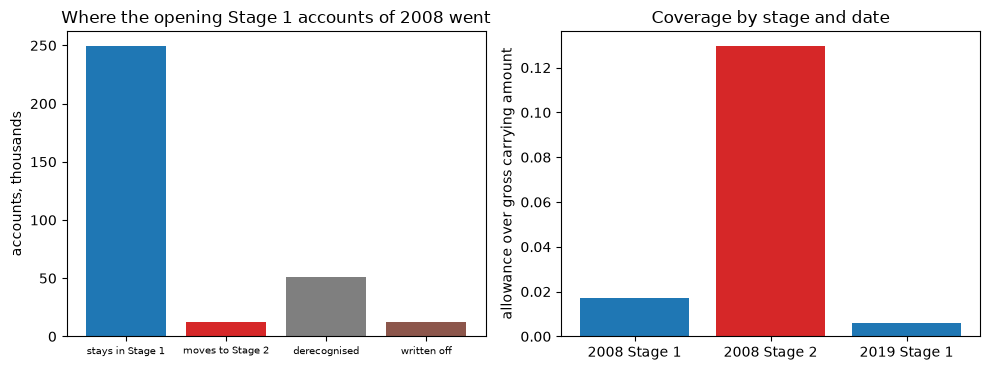

In [9]:
# Read the stage flows of the crisis year and the stage summary of both dates, and draw them
flows = out["stage_flows"]["flows"]
from_stage1 = {f["target"]: f["accounts"] for f in flows if f["source"] == "stage1"}
opening = sum(from_stage1.values())
print("opening Stage 1 accounts:", opening, "| moved to Stage 2:", from_stage1["stage2"])
print("share:", round(from_stage1["stage2"] / opening, 4))
coverage = {}
for name, art in (("2008-12-31", crisis), ("2019-12-31", calm)):
    rows = {r["stage"]: r for r in art["outputs"]["stage_summary"]["rows"]}
    coverage[name] = [rows[s]["coverage"] for s in ("stage1", "stage2")]
    print(name, "| accounts by stage:", [rows[s]["accounts"] for s in ("stage1", "stage2", "stage3")])
    print("   coverage:", [round(rows[s]["coverage"], 4) for s in ("stage1", "stage2", "stage3")])
ratio_2008 = coverage["2008-12-31"][1] / coverage["2008-12-31"][0]
print("coverage of Stage 2 over Stage 1, 2008:", round(ratio_2008, 3))

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
targets = ["stage1", "stage2", "derecognised", "written-off"]
names = ["stays in Stage 1", "moves to Stage 2", "derecognised", "written off"]
colors = ["tab:blue", "tab:red", "tab:grey", "tab:brown"]
left.bar(names, [from_stage1[t] / 1000 for t in targets], color=colors)
left.set_ylabel("accounts, thousands")
left.set_title("Where the opening Stage 1 accounts of 2008 went")
left.tick_params(axis="x", labelsize=7)
right.bar(["2008 Stage 1", "2008 Stage 2", "2019 Stage 1"],
          [coverage["2008-12-31"][0], coverage["2008-12-31"][1], coverage["2019-12-31"][0]],
          color=["tab:blue", "tab:red", "tab:blue"])
right.set_ylabel("allowance over gross carrying amount")
right.set_title("Coverage by stage and date")
fig.tight_layout()
plt.show()

In the crisis year 12,407 of the 325,731 accounts that opened in Stage 1 moved to Stage 2, 3.81%, and a larger number left the book by repayment or write-off. Stage 2 coverage was 12.97% against 1.71% for Stage 1, 7.59 times higher, which is the cliff of notebook 01 seen in the book. On 2019-12-31 no loan was in Stage 2 and the coverage of Stage 1 was 0.58%, a calm date where the staging has nothing to move.

## Results

**Answer:** Under the committed policy 16 of the 400 sampled loans, 0.04 of the sample, move from the Stage 1 measure to the lifetime ECL of Stage 2, all by the relative-and-absolute rule because their annualised PD rose by at least the multiplier of their band; the multiplier schedule decides how many, since scaling it by 0.75 flags 109 loans and by 1.25 flags 2, while the absolute floor (16 loans, or 15 at a floor of 0.02) and the threefold ratio (35 loans, only when it is lowered to 2) hardly matter.

- **Two accounts, one rule.** The Stage 1 account A0001 has an annualised PD of 0.0029 at origination and 0.0034 now, a ratio of 1.19: no significant increase. The Stage 2 account A0005 goes from 0.0114 to 0.0306, a ratio of 2.69 and a difference of 0.0192: its origination PD falls in the band whose multiplier is 2.5, so the ratio and the floor are both met.
- **The threefold backstop never acts here.** The largest ratio of the sample is 2.76, so no account is at three times its origination PD, and the threefold ratio changes the count only when it is lowered to 2.
- **The multiplier schedule is the lever.** This is the quantity a validator has to challenge, together with its calibration to the origination PD, and the threshold must not loosen when conditions worsen (EBA/Rep/2023/36 paragraph 33).
- **The qualitative rules are exact at their boundaries.** 30 days past due is Stage 1 and 31 is Stage 2 by the backstop; 90 is Stage 3; forbearance is Stage 2; when two reasons hold, the trigger of higher precedence is the one reported. The low credit risk exemption suppressed the relative-and-absolute trigger of the account whose PD rose from 0.002 to 0.0082 and left every days-past-due and forbearance case alone.
- **Probation and the collective view.** With a probation of 12 months, only the account cured 3 months ago stays in Stage 2, with trigger cure-probation. The collective targets are amounts to turn into accounts, never to add to the allowance.
- **A crisis year and a calm year.** In 2008, 12,407 of the 325,731 opening Stage 1 accounts (3.81%) moved to Stage 2, and the coverage of Stage 2 was 12.97% against 1.71% for Stage 1, 7.59 times higher. On 2019-12-31 no loan was in Stage 2 and the coverage of Stage 1 was 0.58%.

What this notebook does not show: the pipeline stages loans with the quantitative rule only, because the file has no delinquency history (finding `F-NO-DELINQUENCY`), so Stage 3 holds no balance at a date and the days-past-due cases are constructed. The 400 accounts are a sample, while the stage flows and summaries are those of the whole book. Whether the staging predicts defaults is a validation question, answered in notebook 05.

## Summary

- Staging compares the PD now with the PD at origination on the same window, both annualised, and the engine applies a relative-and-absolute rule with a threefold backstop; the parameters are policy, not regulation.
- `allocate_stages` returns the stage and the trigger that decided, with a fixed precedence: default, days past due, forbearance, watch list, collective, relative-and-absolute, threefold. The low credit risk exemption touches only the two quantitative triggers.
- On C06 at the crisis date 16 of 400 sampled accounts are in Stage 2, and the multiplier schedule, not the floor or the threefold ratio, decides how many.
- Probation and the collective transfer are separate functions: the first holds a cured loan in Stage 2, the second only reports a target amount.
- The stage flows and the coverage by stage are what an IFRS 7 table needs: Stage 2 coverage was 7.59 times that of Stage 1 in 2008, and there was no Stage 2 in 2019.

**What to try next.** Change `probation_months` to 6 and to 24, scale the multiplier schedule by 0.5 (the engine will refuse it: multipliers must be at least 1), and read the message. Then continue with notebook 03, which weights the scenarios behind these PDs.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2021), IFRS 9 implementation by EU institutions, monitoring report, EBA/Rep/2021/35. https://www.eba.europa.eu/sites/default/files/document_library/Publications/Reports/2021/1024609/IFRS9%20monitoring%20report.pdf
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- Botha, A. and Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, equations 6 to 10. https://arxiv.org/abs/2507.15441